# BM25

**Summary** (dev, 241 queries)
- **Baseline = default BM25**: name + categories + path + description, stemming, k1 0.9, b 0.4. **Rcap@100 0.706**, nDCG@10 0.691.
- Rule: adopt a change only if **significantly better** (paired permutation test, p < 0.05).
- **Stemming** (+4.5) and **description** (+5.6) are significant. Attributes (+1.5, p = 0.12) and tuned k1/b (+0.6, p = 0.21) are not.
- Best of 420 grid settings: +1.6 over default, **not significant** (p = 0.11).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from product_search.eval.metrics import RECALL_KS
from product_search.eval.stats import paired_permutation_test
from product_search.runs import RUNS_DIR, read_json

RULE_P = 0.05
RUNS = {"default": RUNS_DIR / "bm25_default", "tuned": RUNS_DIR / "bm25_tuned"}
HEADLINE = ["Rcap@100_exact", "nDCG@10", "MRR@10", "R@1000_exact"]

summary = {name: read_json(path / "metrics_dev.json") for name, path in RUNS.items()}
per_query = {
    name: pd.read_parquet(path / "metrics_per_query_dev.parquet") for name, path in RUNS.items()
}
meta = {name: read_json(path / "meta.json") for name, path in RUNS.items()}
grid = pd.read_parquet(RUNS_DIR / "bm25_grid" / "grid.parquet")
ablations = pd.read_csv(RUNS_DIR / "bm25_grid" / "ablations.csv")

## 1. Decisions

One part removed from the best grid setting at a time; drop in **Rcap@100 Exact**.

In [2]:
DECISIONS = {
    "stemming off": ("Stemming", "on"),
    "fields: name+cat+path": ("Description", "keep"),
    "fields: name+cat+path+desc": ("Attributes", "leave out"),
    "default k1 0.9, b 0.4": ("k1, b", "default"),
}
decisions = ablations[ablations["change"].isin(DECISIONS)].copy()
decisions["part"] = decisions["change"].map(lambda c: DECISIONS[c][0])
decisions["points"] = (decisions["diff_vs_best"] * 100).round(1)
decisions["p"] = decisions["p_value"].round(3)
decisions["significant"] = decisions["p_value"] < RULE_P
decisions["choice"] = decisions["change"].map(lambda c: DECISIONS[c][1])
display(decisions[["part", "points", "p", "significant", "choice"]].set_index("part"))

,points,p,significant,choice
part,,,,
Stemming,-4.5,0.000,True,on
Description,-5.6,0.001,True,keep
Attributes,-1.5,0.120,False,leave out
"k1, b",-0.6,0.215,False,default


## 2. Default vs best grid setting

In [3]:
rows = []
for metric in HEADLINE:
    d, t = summary["default"][metric], summary["tuned"][metric]
    diff, p = paired_permutation_test(per_query["default"][metric], per_query["tuned"][metric])
    rows.append(
        {
            "metric": metric,
            "default": f"{d['mean']:.3f} [{d['low']:.3f}, {d['high']:.3f}]",
            "best grid": f"{t['mean']:.3f} [{t['low']:.3f}, {t['high']:.3f}]",
            "diff": round(diff, 3),
            "p": round(p, 3),
        }
    )
display(pd.DataFrame(rows).set_index("metric"))

,default,best grid,diff,p
metric,,,,
Rcap@100_exact,"0.706 [0.658, 0.753]","0.722 [0.676, 0.767]",0.016,0.105
nDCG@10,"0.691 [0.650, 0.730]","0.681 [0.639, 0.722]",-0.010,0.261
MRR@10,"0.713 [0.658, 0.770]","0.699 [0.645, 0.756]",-0.014,0.455
R@1000_exact,"0.915 [0.883, 0.943]","0.916 [0.885, 0.943]",0.001,0.900


## 3. Recall curve

Share of right products in the top k. **Exact**: only perfect matches count. **Exact + Partial**: right product type with a detail missing also counts. Shaded: 95% interval.

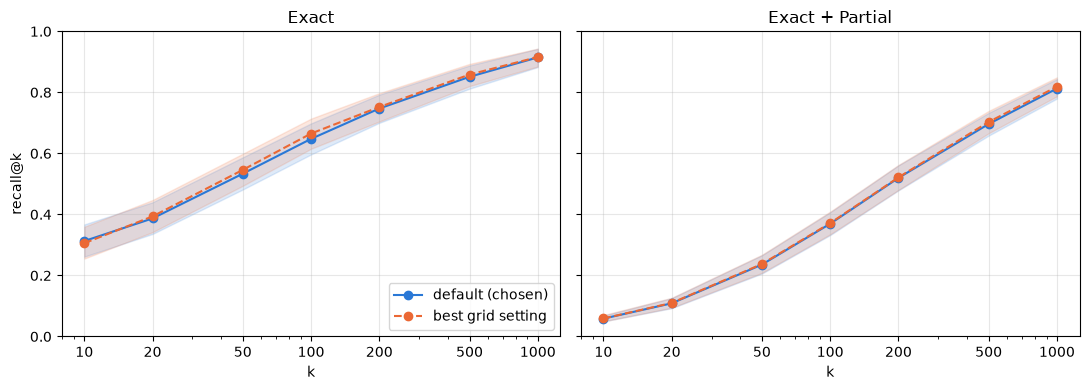

In [4]:
STYLE = {
    "default": {"color": "#2a78d6", "linestyle": "-", "label": "default (chosen)"},
    "tuned": {"color": "#eb6834", "linestyle": "--", "label": "best grid setting"},
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, level, title in [(axes[0], "exact", "Exact"), (axes[1], "any", "Exact + Partial")]:
    for name, style in STYLE.items():
        stats = [summary[name][f"R@{k}_{level}"] for k in RECALL_KS]
        ax.plot(RECALL_KS, [s["mean"] for s in stats], marker="o", **style)
        low, high = [s["low"] for s in stats], [s["high"] for s in stats]
        ax.fill_between(RECALL_KS, low, high, color=style["color"], alpha=0.15)
    ax.set(xscale="log", xlabel="k", title=title, ylim=(0, 1))
    ax.set_xticks(RECALL_KS, [str(k) for k in RECALL_KS])
    ax.grid(alpha=0.3)
axes[0].set_ylabel("recall@k")
axes[0].legend(loc="lower right")
plt.tight_layout()

## 4. k1 and b

Rcap@100 Exact for all fields with stemming. **Flat surface (0.70-0.72)**: tuning k1/b does not pay off.

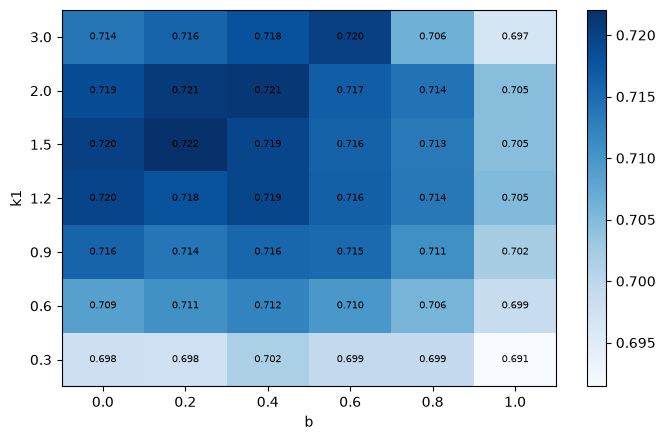

In [5]:
cell = grid[(grid["fields"] == "all") & grid["stemming"]]
heat = cell.groupby(["k1", "b"])["Rcap@100_exact"].mean().unstack("b")

fig, ax = plt.subplots(figsize=(7, 4.5))
image = ax.imshow(heat.values, cmap="Blues", aspect="auto", origin="lower")
ax.set_xticks(range(len(heat.columns)), heat.columns)
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set(xlabel="b", ylabel="k1")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.values[i, j]:.3f}", ha="center", va="center", fontsize=7)
fig.colorbar(image)
plt.tight_layout()

## 5. Cost

Tower, background apps closed.

In [6]:
cost_rows = {}
for name in RUNS:
    c = meta[name]["cost"]
    cost_rows[name] = {
        "index (MB)": c["index_size_mb"],
        "indexing (s)": c["indexing_seconds"],
        **{f"{p} (ms)": c["latency"][f"{p}_ms"] for p in ("p50", "p99")},
    }
display(pd.DataFrame(cost_rows).round(2))

,default,tuned
index (MB),16.24,46.96
indexing (s),2.18,5.96
p50 (ms),0.69,0.63
p99 (ms),1.32,1.53
